# Notebook 1: Preprocessing & Ekstraksi Fitur Audio

Notebook ini bertugas menyiapkan seluruh data audio sebelum dilatih oleh model Deep Learning.

**Tahapan yang dilakukan:**
- Deduplikasi file audio menggunakan hash MD5 agar tidak ada rekaman ganda.
- Split data 80:10:10 (Train/Val/Test) secara stratified **sebelum** augmentasi, untuk mencegah data leakage.
- Augmentasi audio (time-shift dengan zero-padding, pitch shift, dan penambahan noise) hanya pada data Train.
- Ekstraksi fitur MFCC (40 koefisien x 130 frame) dan SDCC (40 koefisien x 130 frame).
- Normalisasi Z-Score yang dihitung murni dari data Train, lalu diterapkan ke Val dan Test.
- Seluruh hasil disimpan ke file `.npz` untuk digunakan oleh Notebook 2 sampai 5.

In [1]:
import os
import hashlib
import random
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

# 1. Kunci Random Seed agar eksperimen 100% Reproducible
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# 2. Pencarian Dinamis Direktori Dataset Kaggle
CANDIDATE_PATHS = [
    "/kaggle/input/maqam-in-holy-quran-dataset/quran_data",
    "/kaggle/input/datasets/murtadhanajim/maqam-in-holy-quran-dataset/quran_data"
]

DATA_DIR = None
for p in CANDIDATE_PATHS:
    if os.path.exists(p) and os.path.isdir(p):
        DATA_DIR = p
        break

if DATA_DIR is None:
    for root, dirs, _ in os.walk("/kaggle/input"):
        if "quran_data" in dirs:
            DATA_DIR = os.path.join(root, "quran_data")
            break
        if any(cls_name in dirs for cls_name in ['Ajam', 'Bayat', 'Hijaz', 'Kurd', 'Nahawand', 'Rast', 'Saba', 'Seka']):
            DATA_DIR = root
            break

if DATA_DIR is None:
    raise FileNotFoundError("Direktori dataset 'quran_data' tidak ditemukan di /kaggle/input! Pastikan dataset murtadhanajim/maqam-in-holy-quran-dataset sudah ditambahkan.")

OUTPUT_DATASET_PATH = "/kaggle/working/maqam_2d_dataset.npz"
OUTPUT_SCALER_PATH = "/kaggle/working/scaler_params.npz"

# 3. Pemetaan Nama Folder ke Nama Kelas Baku Indonesia
LABEL_MAP = {
    'Ajam': 'Ajam',
    'Bayat': 'Bayati',
    'Hijaz': 'Hijaz',
    'Kurd': 'Kurdi',
    'Nahawand': 'Nahawand',
    'Rast': 'Rast',
    'Saba': 'Saba',
    'Seka': 'Sikah'
}
CLASS_NAMES = ['Ajam', 'Bayati', 'Hijaz', 'Kurdi', 'Nahawand', 'Rast', 'Saba', 'Sikah']
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# 4. Parameter Konfigurasi Audio & Fitur 2D (MFCC + SDCC)
SR = 22050                 # Sample rate standar (Hz)
DURATION = 3.0             # Durasi klip standar (detik)
TARGET_SAMPLES = int(SR * DURATION)  # Tepat 66.150 sampel
N_FFT = 2048
HOP_LENGTH = 512
TARGET_FRAMES = 130        # 1 + (66150 // 512) = 130 frame waktu

# Parameter MFCC & SDCC (N, d, P, k)
N_MFCC = 13
SDCC_D = 1                 # Jarak frame untuk delta computation
SDCC_P = 3                 # Pergeseran antar-blok delta (frame shift)
SDCC_K = 7                 # Jumlah blok delta yang ditumpuk (13 x 7 = 91 fitur)

print(f"[INFO] Direktori Dataset : {DATA_DIR}")
print(f"[INFO] Output Dataset    : {OUTPUT_DATASET_PATH}")
print(f"[INFO] Target Matriks MFCC : ({TARGET_FRAMES}, {N_MFCC})")
print(f"[INFO] Target Matriks SDCC : ({TARGET_FRAMES}, {N_MFCC * SDCC_K})")


[INFO] Direktori Dataset : /kaggle/input/datasets/murtadhanajim/maqam-in-holy-quran-dataset/quran_data
[INFO] Output Dataset    : /kaggle/working/maqam_2d_dataset.npz
[INFO] Target Matriks MFCC : (130, 13)
[INFO] Target Matriks SDCC : (130, 91)


### 2. Pemindaian File Audio, Deduplikasi Hash MD5, & Stratified Splitting (80:10:10)
Setiap file audio diverifikasi integritasnya dan diperiksa keunikannya melalui MD5 checksum. File duplikat dieliminasi sebelum pembagian data. Pembagian data dilakukan secara bertingkat (*stratified*) berdasarkan label kelas:
- **Train Set (80%)**: Digunakan untuk pelatihan model (satu-satunya set yang akan diaugmentasi).
- **Validation Set (10%)**: Digunakan untuk hyperparameter tuning dan pemantauan *EarlyStopping*.
- **Test Set (10%)**: Data uji murni tanpa augmentasi untuk evaluasi akhir yang tidak bias.


Total file audio unik valid : 3849 file (Duplikat dieliminasi: 20)

Distribusi Jumlah Rekaman per Kelas Maqam:
label_name
Ajam        522
Bayati      356
Hijaz       797
Kurdi       340
Nahawand    350
Rast        537
Saba        518
Sikah       429
Name: count, dtype: int64

Hasil Pembagian Data Asli (Sebelum Augmentasi):
-> Train Set      : 3079 sampel (80%)
-> Validation Set : 385 sampel (10%)
-> Test Set       : 385 sampel (10%)


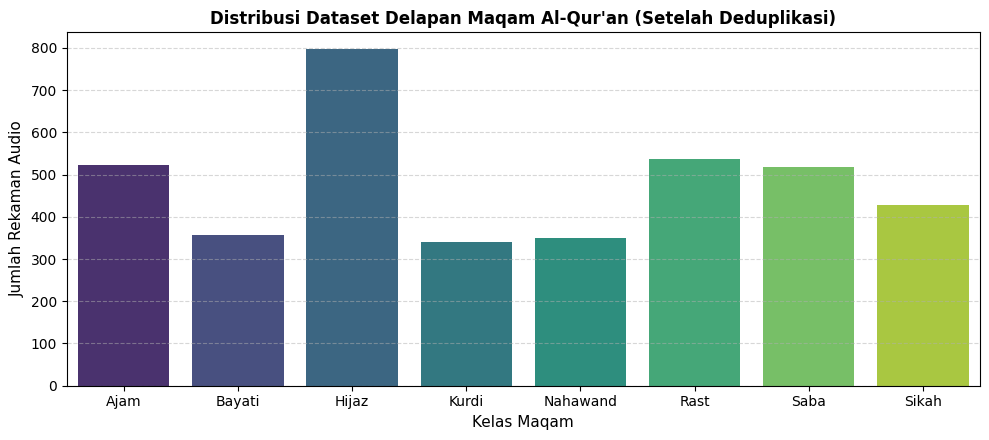

In [2]:
def get_file_md5(filepath):
    hasher = hashlib.md5()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(65536), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

records = []
seen_hashes = set()
duplicate_count = 0

for folder_name, indo_label in LABEL_MAP.items():
    folder_path = os.path.join(DATA_DIR, folder_name)
    if not os.path.isdir(folder_path):
        print(f"[PERINGATAN] Folder tidak ditemukan: {folder_path}")
        continue
        
    for fname in sorted(os.listdir(folder_path)):
        if fname.lower().endswith('.wav'):
            fpath = os.path.join(folder_path, fname)
            if os.path.getsize(fpath) == 0:
                continue
            fhash = get_file_md5(fpath)
            if fhash in seen_hashes:
                duplicate_count += 1
                continue
            seen_hashes.add(fhash)
            
            records.append({
                'filepath': fpath,
                'folder': folder_name,
                'label_name': indo_label,
                'label_idx': CLASS_TO_IDX[indo_label]
            })

df = pd.DataFrame(records)
print(f"Total file audio unik valid : {len(df)} file (Duplikat dieliminasi: {duplicate_count})")
print("\nDistribusi Jumlah Rekaman per Kelas Maqam:")
print(df['label_name'].value_counts().reindex(CLASS_NAMES))

# Stratified Split: 80% Train, 10% Validation, 10% Test
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df['label_idx'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label_idx'], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"\nHasil Pembagian Data Asli (Sebelum Augmentasi):")
print(f"-> Train Set      : {len(train_df)} sampel (80%)")
print(f"-> Validation Set : {len(val_df)} sampel (10%)")
print(f"-> Test Set       : {len(test_df)} sampel (10%)")

# Simpan visualisasi distribusi dataset
plt.figure(figsize=(10, 4.5))
sns.countplot(data=df, x='label_name', hue='label_name', order=CLASS_NAMES, palette='viridis', legend=False)
plt.title("Distribusi Dataset Delapan Maqam Al-Qur'an (Setelah Deduplikasi)", fontsize=12, fontweight='bold')
plt.xlabel("Kelas Maqam", fontsize=11)
plt.ylabel("Jumlah Rekaman Audio", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("/kaggle/working/distribusi_dataset.png", dpi=300)
plt.show()


### 3. Fungsi Standardisasi Audio, Augmentasi Bebas Leakage, & Ekstraksi Fitur 2D

In [3]:
def load_standardized_audio(filepath, sr=SR, target_samples=TARGET_SAMPLES):
    """Memuat audio mono dan menyeragamkan panjang menjadi tepat 3,0 detik."""
    y, _ = librosa.load(filepath, sr=sr, mono=True)
    if len(y) < target_samples:
        # Zero-padding di akhir jika durasi kurang dari 3 detik
        pad_width = target_samples - len(y)
        y = np.pad(y, (0, pad_width), mode='constant')
    elif len(y) > target_samples:
        # Center-cropping agar cengkok utama di bagian tengah rekaman tertangkap
        start = (len(y) - target_samples) // 2
        y = y[start : start + target_samples]
    return y.astype(np.float32)

def augment_audio(y, sr=SR):
    """
    Augmentasi audio yang aman untuk karakter modal maqam:
    1. Time Shifting acak dengan Zero-Padding (menghindari diskontinuitas fase np.roll)
    2. Pitch Shifting ringan (+- 0.5 hingga 1 semitone secara acak)
    3. Gaussian White Noise ringan
    """
    y_aug = y.copy()
    
    # 1. Time Shifting dengan Zero-Padding
    max_shift = int(0.20 * sr)  # Maksimal pergeseran +-0.20 detik
    shift = np.random.randint(-max_shift, max_shift)
    if shift > 0:
        # Geser ke kanan, pad nol di awal
        y_aug = np.pad(y_aug, (shift, 0), mode='constant')[:len(y_aug)]
    elif shift < 0:
        # Geser ke kiri, pad nol di akhir
        y_aug = np.pad(y_aug, (0, -shift), mode='constant')[-shift:]
        
    # 2. Pitch Shifting terkontrol secara probabilistik (50% probabilitas)
    if np.random.rand() > 0.5:
        n_steps = float(np.random.choice([-1.0, -0.5, 0.5, 1.0]))
        y_aug = librosa.effects.pitch_shift(y=y_aug, sr=sr, n_steps=n_steps)
        
    # 3. Penambahan Gaussian White Noise ringan
    noise_amp = np.random.uniform(0.002, 0.005)
    noise = np.random.normal(0, noise_amp, size=y_aug.shape)
    y_aug = y_aug + noise
    
    return y_aug.astype(np.float32)

def compute_sdcc(mfcc_matrix, d=SDCC_D, P=SDCC_P, k=SDCC_K):
    """
    Menghitung matriks Shifted Delta Cepstral Coefficients (SDCC) dari matriks MFCC (T, N).
    Rumus: Delta(t) = c(t + d) - c(t - d), lalu menumpuk k blok dengan pergeseran P frame.
    Output shape: (T, N * k) -> (130, 91)
    """
    T, N = mfcc_matrix.shape
    padded_for_delta = np.pad(mfcc_matrix, ((d, d), (0, 0)), mode='edge')
    delta = padded_for_delta[2 * d:, :] - padded_for_delta[:-2 * d, :]  # Shape: (T, N)

    max_shift = (k - 1) * P
    padded_delta = np.pad(delta, ((0, max_shift), (0, 0)), mode='edge')

    sdcc_blocks = [padded_delta[i * P : i * P + T, :] for i in range(k)]
    sdcc_matrix = np.concatenate(sdcc_blocks, axis=1)
    return sdcc_matrix.astype(np.float32)

def extract_features_2d(y):
    """Mengekstrak matriks 2D MFCC (130, 13) dan SDCC (130, 91) dari sinyal audio 3 detik."""
    mfcc = librosa.feature.mfcc(
        y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH
    ).T  # Transpose ke bentuk (Frame, Koefisien) -> (130, 13)
    
    # Pastikan dimensi frame tepat TARGET_FRAMES (130)
    if mfcc.shape[0] < TARGET_FRAMES:
        mfcc = np.pad(mfcc, ((0, TARGET_FRAMES - mfcc.shape[0]), (0, 0)), mode='edge')
    else:
        mfcc = mfcc[:TARGET_FRAMES, :]
        
    mfcc = mfcc.astype(np.float32)
    sdcc = compute_sdcc(mfcc, d=SDCC_D, P=SDCC_P, k=SDCC_K)
    return mfcc, sdcc


### 4. Eksekusi Ekstraksi Fitur pada Train, Validation, dan Test Set
- Khusus untuk `Train Set`, setiap sampel audio diekstrak versi aslinya serta 1 versi ter-augmentasi, menghasilkan $2 \times N_{train}$ sampel latih.
- Untuk `Validation Set` dan `Test Set`, **hanya versi asli tanpa augmentasi** yang diekstrak untuk menjamin objektivitas evaluasi model.


In [4]:
def build_dataset_split(dataframe, is_train=False, desc="Processing"):
    X_mfcc_list, X_sdcc_list, y_list = [], [], []
    
    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe), desc=desc):
        try:
            y_audio = load_standardized_audio(row['filepath'])
            label = row['label_idx']
            
            # 1. Ekstraksi data audio asli
            mfcc_orig, sdcc_orig = extract_features_2d(y_audio)
            X_mfcc_list.append(mfcc_orig)
            X_sdcc_list.append(sdcc_orig)
            y_list.append(label)
            
            # 2. Khusus data Training: tambahkan versi augmentasi
            if is_train:
                y_aug = augment_audio(y_audio)
                mfcc_aug, sdcc_aug = extract_features_2d(y_aug)
                X_mfcc_list.append(mfcc_aug)
                X_sdcc_list.append(sdcc_aug)
                y_list.append(label)
                
        except Exception as e:
            print(f"[ERROR] Gagal memproses {row['filepath']}: {e}")
            
    return (
        np.array(X_mfcc_list, dtype=np.float32),
        np.array(X_sdcc_list, dtype=np.float32),
        np.array(y_list, dtype=np.int64)
    )

print("Memulai proses ekstraksi fitur 2D MFCC dan SDCC...\n")
X_train_mfcc, X_train_sdcc, y_train = build_dataset_split(train_df, is_train=True, desc="Train Set (+Augmentasi)")
X_val_mfcc, X_val_sdcc, y_val       = build_dataset_split(val_df, is_train=False, desc="Validation Set (Asli)")
X_test_mfcc, X_test_sdcc, y_test    = build_dataset_split(test_df, is_train=False, desc="Test Set (Asli)")

print("\nEkstraksi selesai. Dimensi array fitur:")
print(f"X_train_mfcc: {X_train_mfcc.shape} | X_train_sdcc: {X_train_sdcc.shape} | y_train: {y_train.shape}")
print(f"X_val_mfcc  : {X_val_mfcc.shape} | X_val_sdcc  : {X_val_sdcc.shape} | y_val  : {y_val.shape}")
print(f"X_test_mfcc : {X_test_mfcc.shape} | X_test_sdcc : {X_test_sdcc.shape} | y_test : {y_test.shape}")


Memulai proses ekstraksi fitur 2D MFCC dan SDCC...



Train Set (+Augmentasi):   0%|          | 0/3079 [00:00<?, ?it/s]

Validation Set (Asli):   0%|          | 0/385 [00:00<?, ?it/s]

Test Set (Asli):   0%|          | 0/385 [00:00<?, ?it/s]


Ekstraksi selesai. Dimensi array fitur:
X_train_mfcc: (6158, 130, 13) | X_train_sdcc: (6158, 130, 91) | y_train: (6158,)
X_val_mfcc  : (385, 130, 13) | X_val_sdcc  : (385, 130, 91) | y_val  : (385,)
X_test_mfcc : (385, 130, 13) | X_test_sdcc : (385, 130, 91) | y_test : (385,)


### 5. Normalisasi Z-Score Bebas Data Leakage & Penyimpanan Dataset
Statistik normalisasi ($\mu$ dan $\sigma$) **dihitung secara ketat hanya dari Train Set**, kemudian digunakan untuk mentransformasikan Validation Set dan Test Set. Hal ini menjamin bahwa informasi distribusi data uji tidak pernah bocor ke dalam proses pemodelan.

Label nama kelas dikonversi secara eksplisit ke list string Python murni (`str`) guna menghindari tipe data `np.str_` yang berpotensi memicu kendala serialisasi pada runtime TensorFlow/Kaggle.


In [5]:
# Hitung statistik normalisasi Z-Score HANYA dari Train Set
mfcc_mean = np.mean(X_train_mfcc, axis=(0, 1), keepdims=True).astype(np.float32)
mfcc_std  = np.std(X_train_mfcc, axis=(0, 1), keepdims=True).astype(np.float32)

sdcc_mean = np.mean(X_train_sdcc, axis=(0, 1), keepdims=True).astype(np.float32)
sdcc_std  = np.std(X_train_sdcc, axis=(0, 1), keepdims=True).astype(np.float32)

EPS = 1e-8

# Terapkan standarisasi Z-Score ke seluruh subset
X_train_mfcc = (X_train_mfcc - mfcc_mean) / (mfcc_std + EPS)
X_val_mfcc   = (X_val_mfcc   - mfcc_mean) / (mfcc_std + EPS)
X_test_mfcc  = (X_test_mfcc  - mfcc_mean) / (mfcc_std + EPS)

X_train_sdcc = (X_train_sdcc - sdcc_mean) / (sdcc_std + EPS)
X_val_sdcc   = (X_val_sdcc   - sdcc_mean) / (sdcc_std + EPS)
X_test_sdcc  = (X_test_sdcc  - sdcc_mean) / (sdcc_std + EPS)

# Validasi ketat tidak adanya nilai NaN atau Tak Hingga
assert not np.isnan(X_train_mfcc).any() and not np.isnan(X_train_sdcc).any(), "Ditemukan nilai NaN pada data training!"
assert not np.isnan(X_val_mfcc).any() and not np.isnan(X_val_sdcc).any(), "Ditemukan nilai NaN pada data validation!"
assert not np.isnan(X_test_mfcc).any() and not np.isnan(X_test_sdcc).any(), "Ditemukan nilai NaN pada data test!"

# Simpan array class_names sebagai tipe data string Python murni
clean_class_names = np.array([str(c) for c in CLASS_NAMES], dtype=object)

# 1. Simpan dataset fitur 2D terkompresi untuk Notebook 2, 3, 4, dan 5
np.savez_compressed(
    OUTPUT_DATASET_PATH,
    X_train_mfcc=X_train_mfcc,
    X_train_sdcc=X_train_sdcc,
    y_train=y_train,
    X_val_mfcc=X_val_mfcc,
    X_val_sdcc=X_val_sdcc,
    y_val=y_val,
    X_test_mfcc=X_test_mfcc,
    X_test_sdcc=X_test_sdcc,
    y_test=y_test,
    class_names=clean_class_names
)

# 2. Simpan parameter scaler & konfigurasi lengkap untuk Prototipe Web Deployment
np.savez(
    OUTPUT_SCALER_PATH,
    mfcc_mean=mfcc_mean,
    mfcc_std=mfcc_std,
    sdcc_mean=sdcc_mean,
    sdcc_std=sdcc_std,
    class_names=clean_class_names,
    sr=SR,
    duration=DURATION,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    target_frames=TARGET_FRAMES,
    n_mfcc=N_MFCC,
    sdcc_d=SDCC_D,
    sdcc_p=SDCC_P,
    sdcc_k=SDCC_K
)

size_dataset_mb = os.path.getsize(OUTPUT_DATASET_PATH) / (1024 * 1024)
size_scaler_kb = os.path.getsize(OUTPUT_SCALER_PATH) / 1024
print(f"\n[SUKSES] Dataset fitur 2D tersimpan di : {OUTPUT_DATASET_PATH} ({size_dataset_mb:.2f} MB)")
print(f"[SUKSES] Parameter scaler tersimpan di  : {OUTPUT_SCALER_PATH} ({size_scaler_kb:.2f} KB)")
print("[INFO] Seluruh tahapan Notebook 1 selesai dengan sukses!")



[SUKSES] Dataset fitur 2D tersimpan di : /kaggle/working/maqam_2d_dataset.npz (311.72 MB)
[SUKSES] Parameter scaler tersimpan di  : /kaggle/working/scaler_params.npz (4.49 KB)
[INFO] Seluruh tahapan Notebook 1 selesai dengan sukses!
